# Imbalanced Feature Screener on SBA loans

This notebook demonstrates the `ImbalancedFeatureScreener` package on the SBA imbalanced loan dataset.

The workflow: load the cleaned imbalanced dataset, fit the screener, inspect the ranked report, then visualize the summary and a representative feature diagnostic.

## Data leakage guard

We remove `loanstatus`, `paidinfulldate`, `chargeoffdate`, and `grosschargeoffamount` from the analysis up front. These are post-outcome or outcome-derived fields that would leak the target signal into the feature set if left in the dataset.

This is a deliberate feature exclusion, not a modeling choice to be revisited later.

In [1]:
import sys
from pathlib import Path

import pandas as pd

repo_root = Path.cwd().resolve().parent
src_dir = repo_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from imb_feature_screener import ImbalancedFeatureScreener

data_path = repo_root / 'data' / 'sba_user_cleaned_raw_training.csv'
df = pd.read_csv(data_path, low_memory=False)
# Data leakage guard: remove outcome/post-outcome status fields before screening.
# We explicitly exclude the target-like fields that encode the realized loss outcome: 
# `loanstatus`, `paidinfulldate`, `chargeoffdate`, and `grosschargeoffamount`.
# These fields would leak distress information into the candidate features.
leakage_columns = ['loanstatus', 'paidinfulldate', 'chargeoffdate', 'grosschargeoffamount']
df = df.drop(columns=[c for c in leakage_columns if c in df.columns], errors='ignore')
df = df[df['loan_status_r'] != -1].copy()
df['target'] = df['loan_status_r'].astype(int)
print(df.shape)
print(df['target'].value_counts().sort_index().to_string())
X = df.drop(columns=['loan_status_r', 'target'])
y = df['target']
print(f'Features: {len(X.columns)}')
print(f'Attributes: {list(X.columns)}')


/home/rajiv/programming/imbalanced_feature_screener/imb_feature_screener/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(60075, 41)
target
0    54561
1     5514
Features: 39
Attributes: ['asofdate', 'program', 'locationid', 'borrname', 'borrstreet', 'borrcity', 'borrstate', 'borrzip', 'bankname', 'bankfdicnumber', 'bankncuanumber', 'bankstreet', 'bankcity', 'bankstate', 'bankzip', 'grossapproval', 'sbaguaranteedapproval', 'approvaldate', 'approvalfy', 'firstdisbursementdate', 'processingmethod', 'initialinterestrate', 'fixedorvariableinterestind', 'terminmonths', 'naicscode', 'naicsdescription', 'franchisecode', 'franchisename', 'projectcounty', 'projectstate', 'sbadistrictoffice', 'congressionaldistrict', 'businesstype', 'businessage', 'revolverstatus', 'jobssupported', 'collateralind', 'soldsecmrktind', 'loan_age_months']


In [2]:
screener = ImbalancedFeatureScreener(top_k=10, n_splits=3)
screener.fit(X, y)
print(screener.report_.head(10)[['feature','iv','ks_stat','uni_pr_auc','perm_pr_auc','pos_shap','consensus_rank']].to_string(index=False))
print(f'\nSelected features: {screener.selected_features_}')


            feature       iv  ks_stat  uni_pr_auc  perm_pr_auc  pos_shap  consensus_rank
           bankname 0.285467 0.384416    0.241970     0.039284  0.220711             2.0
           bankcity 0.254379 0.361308    0.215642     0.006411  0.137770             4.6
initialinterestrate 0.171651 0.301928    0.197544     0.024657  0.220407             4.6
         bankstreet 0.283352 0.383980    0.241021     0.000584  0.095340             6.8
       terminmonths 0.424299 0.501207    0.060547     0.505749  0.893368             8.2
   naicsdescription 0.094981 0.221856    0.171385     0.003516  0.092320             9.2
           borrname 0.177079 0.093250    0.156662     0.041233  0.135060             9.6
  sbadistrictoffice 0.072508 0.205626    0.156098     0.001020  0.043009            12.0
          bankstate 0.136739 0.292047    0.186696     0.000560  0.005927            13.8
   processingmethod 0.040987 0.195475    0.123414     0.004299  0.067590            13.8

Selected features: [

In [3]:
X_selected = screener.transform(X)
print(X_selected.shape)
print(X_selected.head())


(60075, 10)
   bankname  initialinterestrate  terminmonths  naicsdescription  borrname  \
0  0.031650                 8.25         299.0          0.117999  0.083441   
1  0.091386                 6.74          48.0          0.132439  0.083441   
2  0.088245                 6.74          60.0          0.077680  0.083441   
3  0.027814                 5.00         300.0          0.035380  0.083441   
4  0.091386                 8.49          84.0          0.148449  0.083441   

   sbadistrictoffice  bankstate  processingmethod  projectcounty  borrstreet  
0           0.083334   0.044992          0.061775       0.047062    0.083441  
1           0.111061   0.102359          0.121386       0.132981    0.083441  
2           0.073344   0.050390          0.121386       0.175413    0.083441  
3           0.095336   0.068232          0.061775       0.069908    0.083441  
4           0.095336   0.102359          0.121386       0.088965    0.083441  


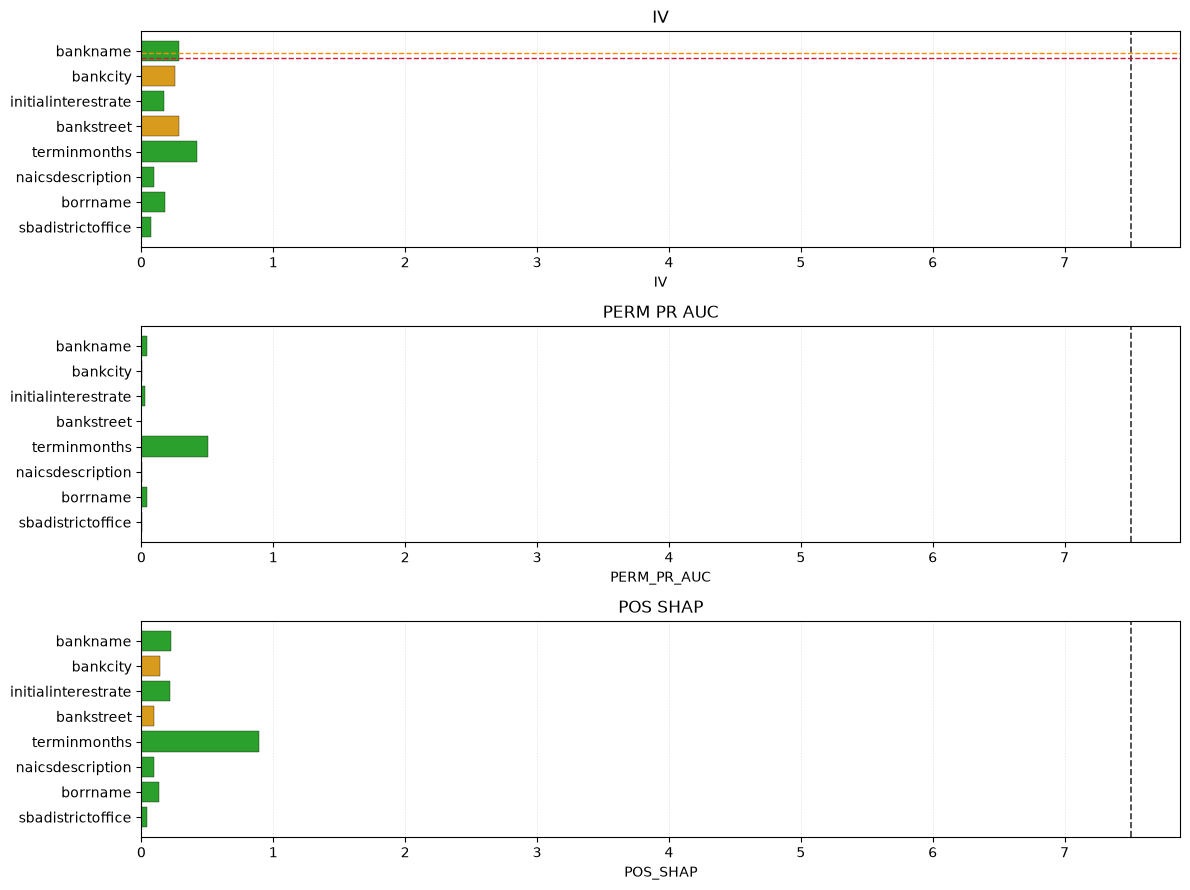

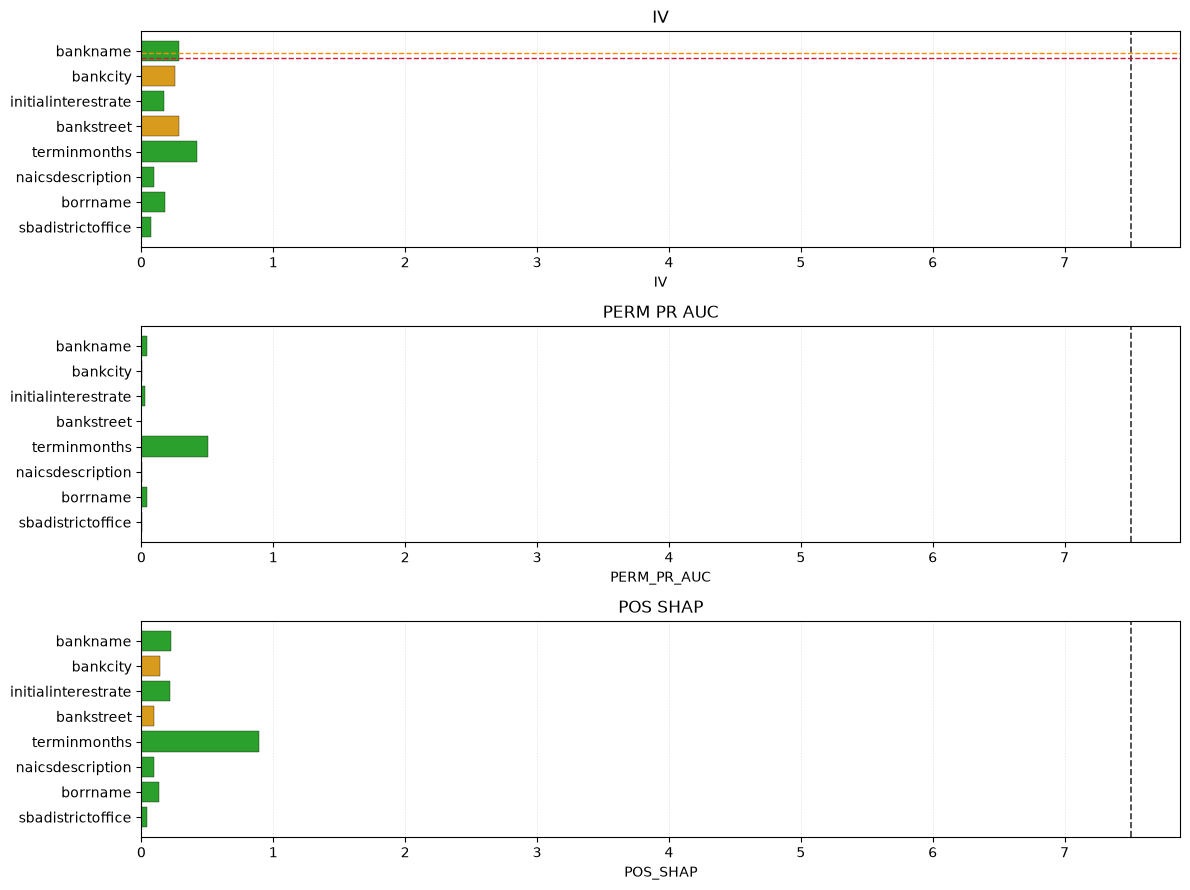

In [4]:
from IPython.display import display

summary_fig = screener.plot_summary(top_n=8)
display(summary_fig)


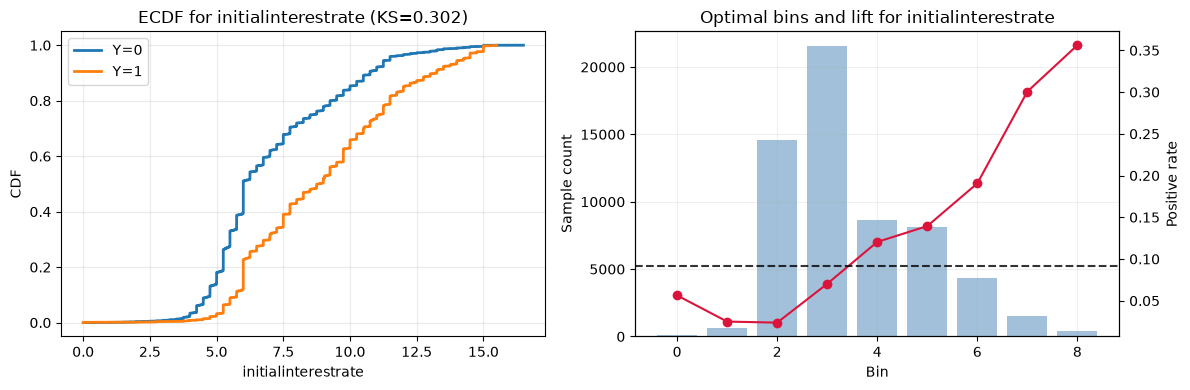

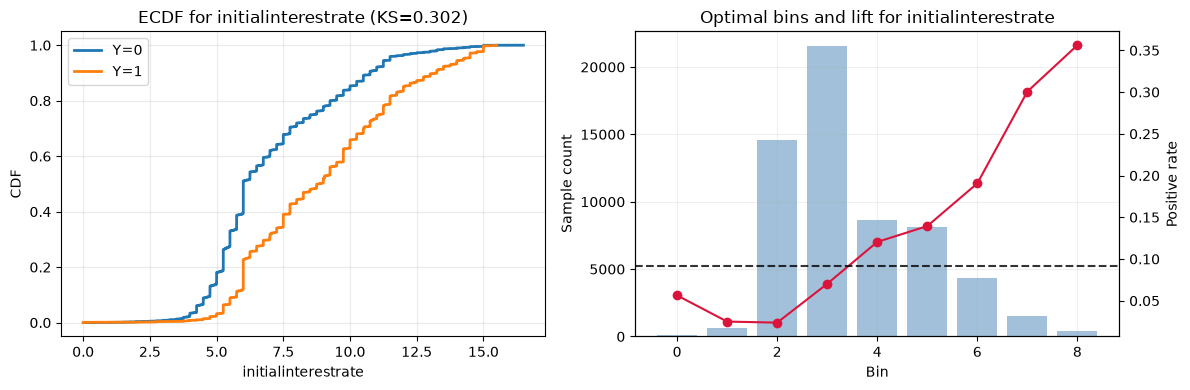

In [5]:
feature = 'initialinterestrate'
feature_fig = screener.plot_feature(X, y, feature=feature, log_x=False)
display(feature_fig)
